# Sales Data Clustering using K-Means and Hierarchical Clustering

**Objective:** Clean and standardize sales data, apply K-Means clustering, and visualize sales groups. The imports also support hierarchical clustering and dendrograms.

**Dataset:** `sales_data_sample.csv` (place it in the same folder as this notebook).

## 1. Install required libraries (if needed)
Skip this cell if the packages are already installed.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

## 3. Load and inspect the dataset

In [8]:
df = pd.read_csv("sales_data_sample.csv", encoding="cp1252")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)

First five rows:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium



Dataset shape: (2823, 25)


## 4. Check dataset quality

In [9]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Column names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

Missing values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int6

## 5. Select and clean numerical features

This notebook uses quantity ordered, price each, and sales. Rows with missing or non-positive values in these features are removed.

In [10]:
data = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]].copy()
data = data.dropna()

data = data[
    (data["QUANTITYORDERED"] > 0) &
    (data["PRICEEACH"] > 0) &
    (data["SALES"] > 0)
].copy()

print("Cleaned data:")
display(data.head())
print("Shape after cleaning:", data.shape)

Cleaned data:


,QUANTITYORDERED,PRICEEACH,SALES
0,30,95.70,2871.00
1,34,81.35,2765.90
2,41,94.74,3884.34
3,45,83.26,3746.70
4,49,100.00,5205.27


Shape after cleaning: (2823, 3)


## 6. Standardize the features

In [11]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
print("Data standardized successfully.")
print(scaled_data[:5])

Data standardized successfully.
[[-0.52289086  0.5969775  -0.37082523]
 [-0.11220131 -0.11445035 -0.42789707]
 [ 0.60650538  0.54938372  0.17944282]
 [ 1.01719493 -0.01975856  0.10470098]
 [ 1.42788447  0.81015797  0.89673966]]


## 7. Find a suitable number of clusters using the Elbow Method

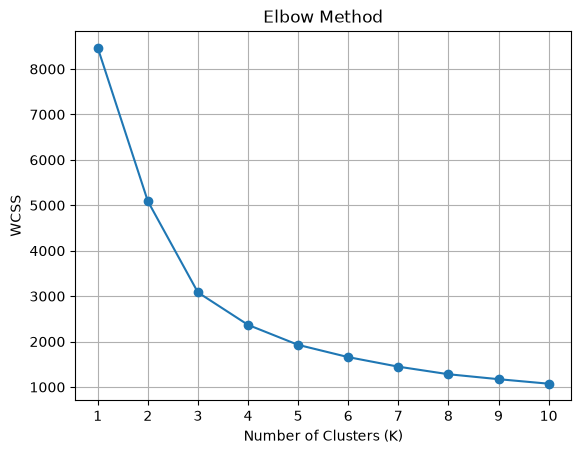

In [ ]:
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_data)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## 8. Apply K-Means clustering

The example uses three clusters, as in the supplied output. Consider the elbow plot when choosing K.

In [13]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data["KMeans_Cluster"] = kmeans.fit_predict(scaled_data)

print("K-Means cluster counts:")
print(data["KMeans_Cluster"].value_counts().sort_index())
display(data.head())

K-Means cluster counts:
KMeans_Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,KMeans_Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,1
4,49,100.00,5205.27,1


## 9. Visualize the K-Means clusters

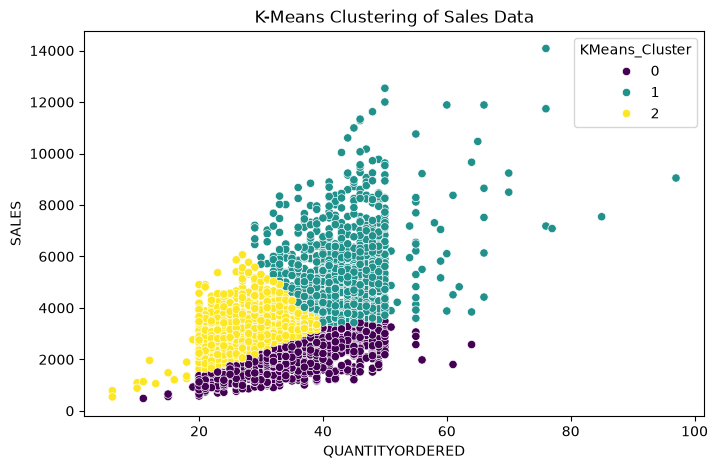

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data, x="QUANTITYORDERED", y="SALES",
    hue="KMeans_Cluster", palette="viridis"
)
plt.title("K-Means Clustering of Sales Data")
plt.show()

## 10. Optional: Hierarchical clustering dendrogram

A dendrogram can become slow or crowded for thousands of rows, so this cell samples at most 100 rows for visualization.

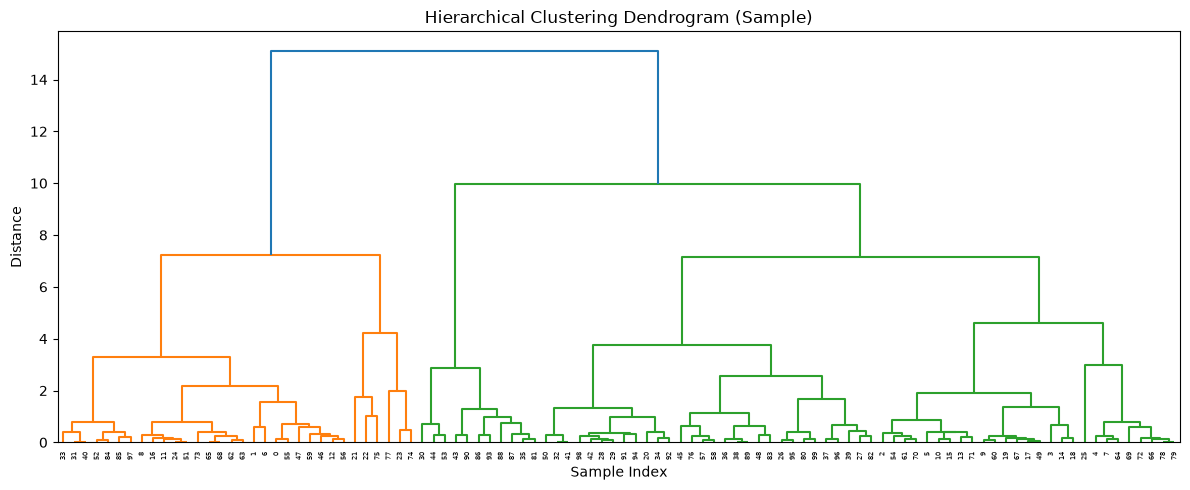

In [15]:
sample_size = min(100, len(scaled_data))
sample_data = scaled_data[:sample_size]
linked = linkage(sample_data, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram (Sample)")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

## Conclusion

The notebook loads and checks the sales dataset, cleans selected numerical features, standardizes them, uses the Elbow Method to inspect possible cluster counts, applies K-Means with three clusters, and visualizes the resulting groups. An optional sampled dendrogram demonstrates hierarchical clustering.

**Note:** Cluster labels are arbitrary group identifiers, not rankings. The `threadpoolctl` warning may appear in some browser-based Pyodide environments and can be non-fatal if clustering completes.